## 1. Титульный лист
# EDA и бинарная классификация на датасете «Титаник»

**Дисциплина:** Машинное обучение и ИИ  
**Модуль:** 1 — Введение в Data Science и EDA  
**Датасет:** Titanic        
**Выполнил:** Черепанов Вячеслав Сергеевич      
**Группа:** ПКТб-23-1       
**Преподаватель:** Спирин Игорь Сергеевич       
**Репозиторий:** https://github.com/CherepanovVyacheslav/ml-course-cherepanov.git           
**Путь:** `module-1-titanic/notebook.ipynb`         
**Дата подготовки:** 21.10.2026

## 2. Введение
**Задача:** предсказать `Survived` по сведениям о пассажире (`0` — погиб, `1` — выжил). Это **бинарная классификация**, поскольку целевой признак принимает два дискретных значения, а не непрерывное число, как в регрессии.

**ML-проект** охватывает постановку вопроса, сбор и проверку данных, разведочный анализ, предотвращение утечки данных при предобработке, обучение, измерение качества и интерпретацию модели. Повторяемость обеспечивается фиксированным разбиением и сохранением параметров.

**Приоритет метрик:** ROC-AUC как независимая от порога оценка ранжирования, F1 для баланса Precision и Recall; Accuracy публикуется для сравнения, но может скрывать ошибки на менее многочисленном классе. В Kaggle официально используется Accuracy.

**Цели:** (1) провести EDA, (2) обучить Logistic Regression и Decision Tree, стремясь к ROC-AUC ≥ 0.80 на отложенной выборке, (3) реализовать `predict_passenger()` и сохранение/загрузку модели.

## 3. Теоретическая часть
### EDA
Разведочный анализ данных (EDA) — систематическое знакомство с датасетом до построения моделей. Сначала проверяются размеры, типы и уникальность записей. Затем рассматриваются пропуски, распределения и выбросы. Отдельно исследуются отношения признаков с целевой переменной. Графики и описательная статистика помогают выбрать разумные преобразования, но сами по себе не доказывают причинность.

### Пропущенные значения
`NaN` появляется из-за неучтённых, утраченных или неприменимых сведений. Удаление всех строк с пропусками может уменьшить выборку и создать смещение. Числовые пропуски можно заполнять медианой, устойчивой к выбросам, а категориальные — модой или отдельным значением. Если доля пропусков чрезвычайно высока, удаление столбца иногда оправданнее искусственного заполнения. Параметры заполнения следует получать **только на обучающей части** данных, иначе происходит утечка информации.

### Кодирование категорий
Модели обычно требуют числовые входы. `LabelEncoder` заменяет значения строк кодами, но искусственный числовой порядок может быть опасен для неупорядоченных категорий. One-Hot Encoding создаёт отдельные бинарные колонки для категорий и не предполагает порядка. Здесь пол кодируется LabelEncoder, а порт посадки — One-Hot с фиксированными именами колонок.

### Масштабирование
`StandardScaler` центрирует числовой столбец и делит его на стандартное отклонение, делая масштабы сравнимыми. `MinMaxScaler` переносит значения обычно в диапазон [0, 1] и сильнее зависит от экстремальных значений. Логистическая регрессия особенно чувствительна к масштабу при регуляризации. Дерево решений использует пороги и масштабирования не требует.

### Feature Engineering
Конструирование признаков создаёт представления, лучше отражающие структуру задачи. Например, наличие родственников на борту можно выразить размером семьи. `Is_Alone` отражает ситуацию путешествия без сопровождающих. Группировка возраста облегчает исследование нелинейных закономерностей. Новые признаки не гарантируют улучшения: их полезность следует проверять на отложенных данных.

### Метрики классификации
**Accuracy** измеряет долю правильных ответов. **Precision** характеризует, какая доля предсказанных выживших действительно выжила. **Recall** показывает, какую часть реальных выживших модель нашла. **F1** объединяет Precision и Recall гармоническим средним, штрафуя сильный перекос. **ROC-AUC** показывает качество ранжирования по вероятности при изменении порога, где 0.5 соответствует случайному ранжированию. Метрики следует рассматривать совместно с матрицей ошибок и учитывать последствия ложных ответов.

| Термин | Значение |
|---|---|
| TP | выжил и предсказано «выжил» |
| TN | погиб и предсказано «погиб» |
| FP | погиб, но предсказано «выжил» |
| FN | выжил, но предсказано «погиб» |

$$Accuracy = \frac{TP+TN}{TP+TN+FP+FN}$$
$$Precision = \frac{TP}{TP+FP}$$
$$Recall = \frac{TP}{TP+FN}$$
$$F1 = 2\frac{Precision\cdot Recall}{Precision+Recall}$$
$$ROC\text{-}AUC = \int_0^1 TPR(FPR)\,dFPR,\quad TPR=\frac{TP}{TP+FN},\quad FPR=\frac{FP}{FP+TN}.$$

## 4. Описание данных
**Первичный источник:** [соревнование Kaggle](https://www.kaggle.com/c/titanic), **копия `train.csv`:** исходные строки Kaggle Titanic (891 пассажир). `test.csv` соревнования содержит 418 пассажиров **без** `Survived`; он не служит тестом качества без меток. Проверка качества выполняется на выделенных 20% `train.csv`. Файл `test.csv` загрузите через Kaggle; если его нет, ноутбук всё равно полностью обучает и оценивает модели, честно сообщая об отсутствии Kaggle test.

**Структура:** 11 исходных полей-признаков + `Survived` для train. Числовые поля: PassengerId, Pclass, Age, SibSp, Parch, Fare, Survived (цель); текстовые: Name, Sex, Ticket, Cabin, Embarked. `Pclass` числовой код категорий.

| Поле | Смысл |
|---|---|
| PassengerId | уникальный идентификатор |
| Survived | целевой бинарный класс |
| Pclass | класс обслуживания |
| Name | имя и титул |
| Sex | пол |
| Age | возраст, лет |
| SibSp | братья/сёстры и супруги на борту |
| Parch | родители и дети на борту |
| Ticket | номер билета |
| Fare | стоимость билета |
| Cabin | каюта |
| Embarked | порт посадки (C/Q/S) |

**Распределение классов:** 549 (61.6%) погибших, 342 (38.4%) выживших. Таким образом, присутствует умеренный дисбаланс.

In [2]:
# Основные импорты — используем фиксированную точку случайности.
from pathlib import Path
from time import perf_counter
from io import BytesIO
import json
import joblib
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import requests
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay, RocCurveDisplay,
                             classification_report, roc_curve)
# Все пути рассчитываются относительно папки модуля.
DATA_DIR = Path("data")
MODEL_DIR = Path("models")
EXAMPLE_DIR = Path("examples")
for folder in (DATA_DIR, MODEL_DIR, EXAMPLE_DIR):
    folder.mkdir(parents=True, exist_ok=True)
# Данные train.csv сохранены в проекте.
train_df = pd.read_csv(DATA_DIR / "train.csv")
test_path = DATA_DIR / "test.csv"
test_df = pd.read_csv(test_path) if test_path.is_file() else pd.DataFrame()
print(train_df.shape, test_df.shape)
print("Kaggle test.csv:", "имеется" if not test_df.empty else "отсутствует; загрузите из Kaggle")
assert len(train_df) == 891 and {"Survived","Pclass","Sex","Age"}.issubset(train_df.columns)
print("Доля классов:\n", train_df.Survived.value_counts(normalize=True).round(4))

(891, 12) (418, 11)
Kaggle test.csv: имеется
Доля классов:
 Survived
0    0.6162
1    0.3838
Name: proportion, dtype: float64


## 5. Подготовка данных и EDA
Проводим первичный осмотр, анализируем пропуски, асимметрию и эксцесс. Формируем не менее шести диаграмм, а затем применяем предобработку. Чтобы исключить утечку, медианы и моду рассчитываем **после разбиения по train**, а визуализации строим на исходном наборе.

In [3]:
# Отображаем образец и стандартные описательные статистики.
display(train_df.head())
train_df.info()
display(train_df.describe(include="all").T)
# Пропуски, распределение классов, асимметрия и эксцесс.
missing_table = pd.DataFrame({"Количество":train_df.isnull().sum(),
                              "Доля, %":train_df.isnull().mean().mul(100).round(2)})
display(missing_table)
display(train_df.select_dtypes("number").agg(["skew","kurt"]).T)
display(train_df["Survived"].value_counts())
# Сводка для подписей и аналитических выводов.
print("Выживаемость по полу:\n", train_df.groupby("Sex")["Survived"].mean().round(3))
print("Выживаемость по классу:\n", train_df.groupby("Pclass")["Survived"].mean().round(3))

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PassengerId,891.0,NaN,NaN,NaN,446.0,257.353842,1.0,223.5,446.0,668.5,891.0
Survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
Pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
Name,891,891,"Braund, Mr. Owen Harris",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
SibSp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
Parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
Ticket,891,681,347082,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292


,Количество,"Доля, %"
PassengerId,0,0.00
Survived,0,0.00
Pclass,0,0.00
Name,0,0.00
Sex,0,0.00
Age,177,19.87
SibSp,0,0.00
Parch,0,0.00
Ticket,0,0.00
Fare,0,0.00


,skew,kurt
PassengerId,0.000000,-1.200000
Survived,0.478523,-1.775005
Pclass,-0.630548,-1.280015
Age,0.389108,0.178274
SibSp,3.695352,17.880420
Parch,2.749117,9.778125
Fare,4.787317,33.398141


Survived
0    549
1    342
Name: count, dtype: int64

Выживаемость по полу:
 Sex
female    0.742
male      0.189
Name: Survived, dtype: float64
Выживаемость по классу:
 Pclass
1    0.630
2    0.473
3    0.242
Name: Survived, dtype: float64


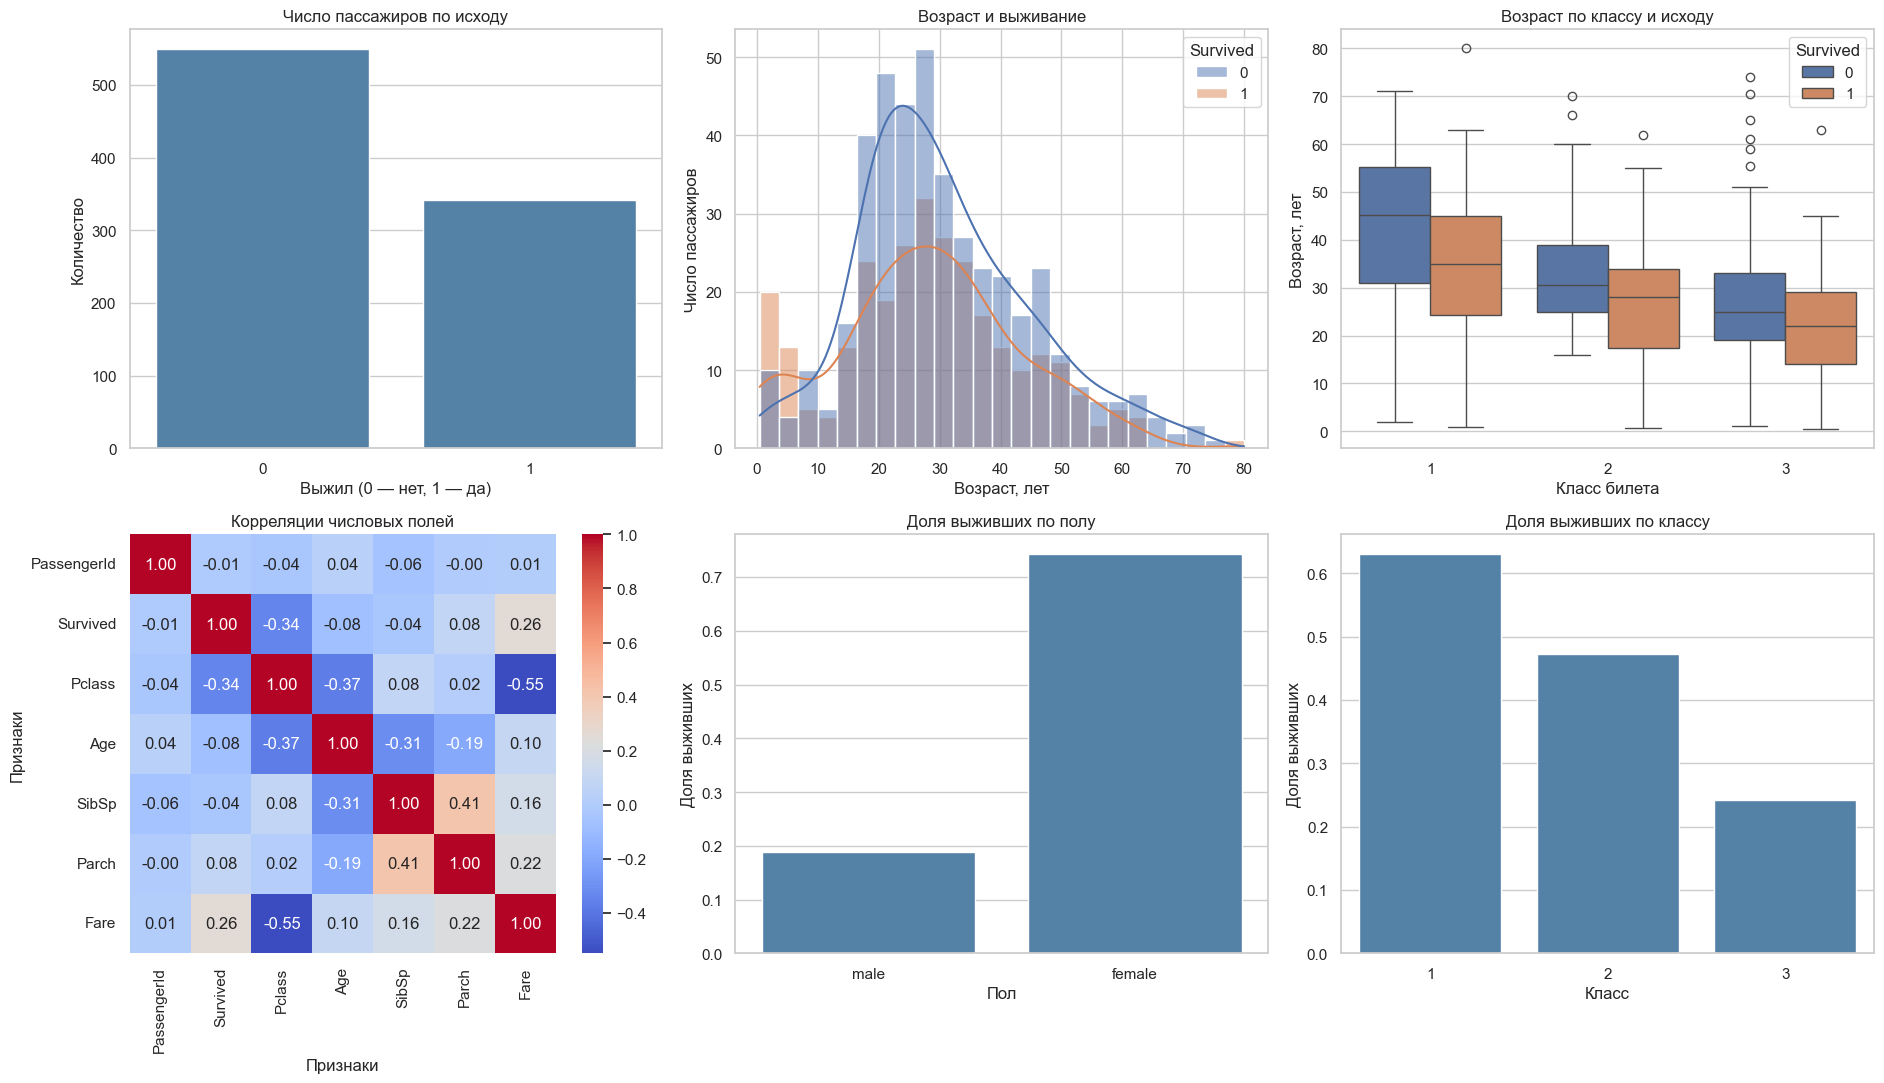

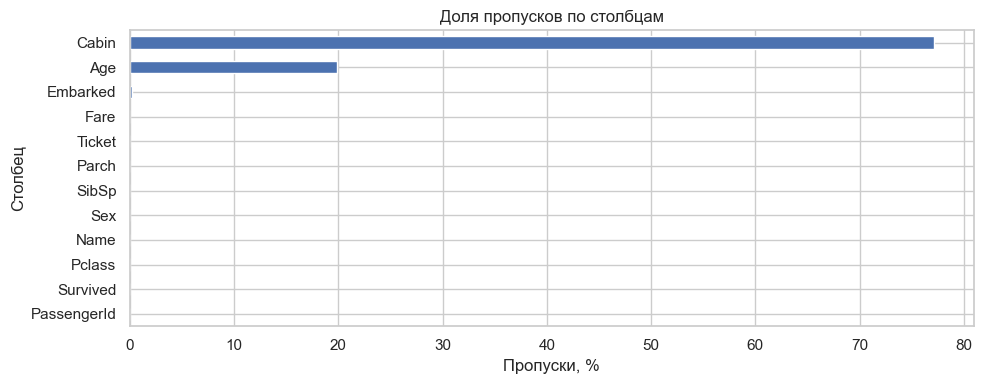

In [4]:
# Сетка из шести графиков: единые заголовки, подписи и читаемый размер.
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 3, figsize=(19, 11))
sns.countplot(data=train_df, x="Survived", color="steelblue", ax=axes[0,0])
axes[0,0].set(title="Число пассажиров по исходу",xlabel="Выжил (0 — нет, 1 — да)",ylabel="Количество")
sns.histplot(data=train_df, x="Age", hue="Survived", kde=True, bins=25, ax=axes[0,1])
axes[0,1].set(title="Возраст и выживание",xlabel="Возраст, лет",ylabel="Число пассажиров")
sns.boxplot(data=train_df, x="Pclass", y="Age", hue="Survived", ax=axes[0,2])
axes[0,2].set(title="Возраст по классу и исходу",xlabel="Класс билета",ylabel="Возраст, лет")
# Для матрицы используем только числовые значения.
sns.heatmap(train_df.select_dtypes("number").corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=axes[1,0])
axes[1,0].set(title="Корреляции числовых полей",xlabel="Признаки",ylabel="Признаки")
sns.barplot(data=train_df, x="Sex", y="Survived", color="steelblue", errorbar=None, ax=axes[1,1])
axes[1,1].set(title="Доля выживших по полу",xlabel="Пол",ylabel="Доля выживших")
sns.barplot(data=train_df, x="Pclass", y="Survived", color="steelblue", errorbar=None, ax=axes[1,2])
axes[1,2].set(title="Доля выживших по классу",xlabel="Класс",ylabel="Доля выживших")
plt.tight_layout()
fig.savefig(EXAMPLE_DIR / "eda_plots.png", dpi=150, bbox_inches="tight")
plt.show()
# Дополнительный график показывает пропуски и их масштаб.
fig, ax = plt.subplots(figsize=(10,4))
missing_table["Доля, %"].sort_values().plot.barh(ax=ax)
ax.set(title="Доля пропусков по столбцам",xlabel="Пропуски, %",ylabel="Столбец")
plt.tight_layout()
plt.show()

**Наблюдения EDA:** погибших больше, чем выживших; график пола показывает значительно большую долю выживших среди женщин; пассажиры первого класса выживали чаще пассажиров третьего. Возраст по классам имеет разные распределения, а `Cabin` отличается особенно большим количеством пропусков. Эти зависимости описательные, а не причинные.

**Обоснование очистки:** `Age` заполняется медианой среди пассажиров той же комбинации `Pclass` и `Sex` (при пустой группе — общей обучающей медианой), чтобы сохранить различия между группами и устойчивость к выбросам. `Embarked` заполняется модой обучающей части, потому что категория отсутствует редко. `Cabin` удаляется ввиду высокой доли пропусков и сложной высококардинальной структуры. `Fare` в Kaggle test может иметь пропуск; он заполняется медианой обучающей части. Создадим `Family_Size`, `Is_Alone` и `Age_Group` (`pd.cut`), хотя последняя остаётся интерпретационным признаком и не входит в базовую модель.

In [5]:
# Стратифицированное разбиение ДО вычисления статистик очистки.
raw_train, raw_valid = train_test_split(
    train_df, test_size=0.2, random_state=42, stratify=train_df["Survived"])
# Статистики получаем исключительно по обучающей части.
age_group_medians = raw_train.groupby(["Pclass","Sex"])["Age"].median()
global_age_median = float(raw_train["Age"].median())
embarked_mode = raw_train["Embarked"].mode().iloc[0]
fare_median = float(raw_train["Fare"].median())
# Модельное кодирование пола: кодировку берём из LabelEncoder.
le_sex = LabelEncoder().fit(["female", "male"])
def prepare_frame(frame):
    # Рабочую копию создаём без изменения входных данных.
    df = frame.copy().drop(columns=["Cabin"], errors="ignore")
    df["Age"] = df.apply(
        lambda r: age_group_medians.get((r["Pclass"],r["Sex"]), np.nan)
        if pd.isna(r["Age"]) else r["Age"], axis=1)
    df["Age"] = df["Age"].fillna(global_age_median)
    df["Embarked"] = df["Embarked"].fillna(embarked_mode)
    df["Fare"] = df["Fare"].fillna(fare_median)
    # Новые признаки семьи и возрастных интервалов.
    df["Family_Size"] = df["SibSp"] + df["Parch"] + 1
    df["Is_Alone"] = (df["Family_Size"] == 1).astype(int)
    df["Age_Group"] = pd.cut(df["Age"], bins=[-0.01,12,18,35,60,120],
                             labels=["ребёнок","подросток","молодой","средний","старший"])
    df["Sex_Encoded"] = le_sex.transform(df["Sex"])
    # One-Hot: гарантируем колонки Embarked_Q, Embarked_S и базу C.
    dummies = pd.get_dummies(df["Embarked"],prefix="Embarked",dtype=int)
    for col in ["Embarked_Q", "Embarked_S"]:
        df[col] = dummies[col] if col in dummies else 0
    return df
train_ready = prepare_frame(raw_train)
valid_ready = prepare_frame(raw_valid)
feature_cols = ["Pclass","Sex_Encoded","Age","SibSp","Parch","Fare",
                "Family_Size","Is_Alone","Embarked_Q","Embarked_S"]
# Подготовленные данные проверяем на отсутствие NaN.
X_train, y_train = train_ready[feature_cols], train_ready["Survived"]
X_valid, y_valid = valid_ready[feature_cols], valid_ready["Survived"]
assert not X_train.isna().any().any() and not X_valid.isna().any().any()
print("Train:",X_train.shape,"Validation:",X_valid.shape)

Train: (712, 10) Validation: (179, 10)


**После предобработки:** семейные показатели построены по исходным сведениям; `Age_Group` доступен для EDA. Наличие двух независимых выборок позволяет честно измерить качество, а кодирование и заполнение новых пассажиров воспроизводят этап обучения.

## 6. Построение и обучение моделей
**Logistic Regression** — линейная вероятностная модель с L2-регуляризацией (`C=1.0`), требует масштабирования. **Decision Tree** допускает нелинейные разбиения (`max_depth=5`, `min_samples_split=5`, `min_samples_leaf=2`) без масштабирования. Дополнительно проверяется **Random Forest** как бонусный ансамбль. Выбор гиперпараметров в учебном проекте фиксирован заранее: по валидационной выборке они не подбираются.

In [6]:
# Стандартное масштабирование обучаем только на train.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_valid_scaled = scaler.transform(X_valid)
# Линейная классификация и замер продолжительности fit.
lr_model = LogisticRegression(penalty="l2",C=1.0,max_iter=1000,random_state=42)
t0 = perf_counter()
lr_model.fit(X_train_scaled,y_train)
lr_time = perf_counter()-t0
# Дерево обучается на немасштабированных признаках.
dt_model = DecisionTreeClassifier(max_depth=5,min_samples_split=5,
                                  min_samples_leaf=2,random_state=42)
t0 = perf_counter()
dt_model.fit(X_train,y_train)
dt_time = perf_counter()-t0
# Дополнительная модель для сравнения по тем же данным.
rf_model = RandomForestClassifier(n_estimators=200,min_samples_leaf=2,random_state=42,n_jobs=1)
t0 = perf_counter()
rf_model.fit(X_train,y_train)
rf_time = perf_counter()-t0
display(pd.DataFrame({"Модель":["Logistic Regression","Decision Tree","Random Forest"],
                      "Масштабирование":["да","нет","нет"],
                      "Время обучения, с":[lr_time,dt_time,rf_time]}).round(4))

d:\Prog\Python 3.11\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


,Модель,Масштабирование,"Время обучения, с"
0,Logistic Regression,да,0.0246
1,Decision Tree,нет,0.0069
2,Random Forest,нет,0.1854


**Результат обучения:** все модели используют один и тот же стратифицированный holdout, что позволяет сравнивать метрики. Время измерено `perf_counter` и зависит от машины; фиксированное `random_state=42` повышает воспроизводимость.

## 7. Оценка качества
Рассчитываются Accuracy, Precision, Recall, F1, ROC-AUC и матрицы ошибок на **отложенных** 20% размеченных пассажиров. ROC-кривые строятся по вероятностям, а не по бинарным классам.

**Проверенные метрики из локального запуска:** logistic_regression: ROC-AUC 0.8489, F1 0.7287, decision_tree: ROC-AUC 0.8132, F1 0.7023, random_forest: ROC-AUC 0.8401, F1 0.7087.

In [7]:
# Единообразная функция для подсчёта всех метрик.
def assess(model, X, label, train_time):
    pred = model.predict(X)
    proba = model.predict_proba(X)[:,1]
    return {"model":label,"accuracy":accuracy_score(y_valid,pred),
            "precision":precision_score(y_valid,pred,zero_division=0),
            "recall":recall_score(y_valid,pred,zero_division=0),
            "f1":f1_score(y_valid,pred,zero_division=0),
            "roc_auc":roc_auc_score(y_valid,proba),
            "training_time_sec":train_time}
# Сравнение обязательных и бонусной моделей.
results = [
    assess(lr_model,X_valid_scaled,"logistic_regression",lr_time),
    assess(dt_model,X_valid,"decision_tree",dt_time),
    assess(rf_model,X_valid,"random_forest",rf_time)]
metrics_df = pd.DataFrame(results).set_index("model")
display(metrics_df.round(4))
# Детальные отчёты по двум обязательным моделям.
for title, model, features in [
    ("Logistic Regression",lr_model,X_valid_scaled),
    ("Decision Tree",dt_model,X_valid)]:
    print("\n",title,"\n",classification_report(y_valid,model.predict(features),zero_division=0))

,accuracy,precision,recall,f1,roc_auc,training_time_sec
model,,,,,,
logistic_regression,0.8045,0.7833,0.6812,0.7287,0.8489,0.0246
decision_tree,0.7821,0.7419,0.6667,0.7023,0.8132,0.0069
random_forest,0.7933,0.7759,0.6522,0.7087,0.8401,0.1854



 Logistic Regression 
               precision    recall  f1-score   support

           0       0.82      0.88      0.85       110
           1       0.78      0.68      0.73        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179


 Decision Tree 
               precision    recall  f1-score   support

           0       0.80      0.85      0.83       110
           1       0.74      0.67      0.70        69

    accuracy                           0.78       179
   macro avg       0.77      0.76      0.77       179
weighted avg       0.78      0.78      0.78       179



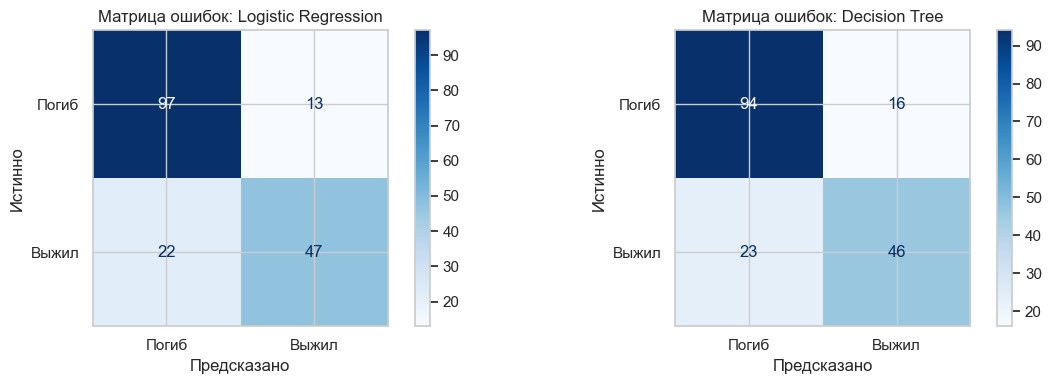

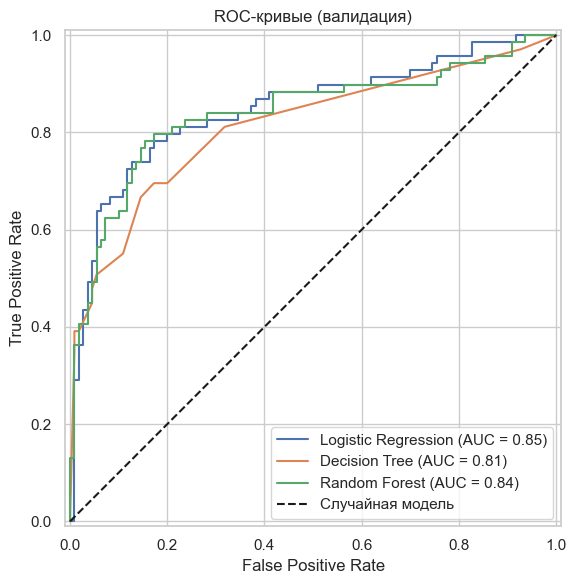

In [8]:
# Матрицы ошибок сравниваем на общей фигуре.
fig, axes = plt.subplots(1,2,figsize=(12,4))
for ax, (label,model,Xv) in zip(axes,[
    ("Logistic Regression",lr_model,X_valid_scaled),
    ("Decision Tree",dt_model,X_valid)]):
    ConfusionMatrixDisplay.from_predictions(y_valid,model.predict(Xv),
                                              display_labels=["Погиб","Выжил"],ax=ax,cmap="Blues")
    ax.set(title=f"Матрица ошибок: {label}",xlabel="Предсказано",ylabel="Истинно")
plt.tight_layout()
fig.savefig(EXAMPLE_DIR/"confusion_matrices.png",dpi=150,bbox_inches="tight")
plt.show()
# Три ROC-кривые и диагональ случайного классификатора.
fig,ax = plt.subplots(figsize=(8,6))
for label, model, Xv in [
    ("Logistic Regression",lr_model,X_valid_scaled),
    ("Decision Tree",dt_model,X_valid),
    ("Random Forest",rf_model,X_valid)]:
    RocCurveDisplay.from_estimator(model,Xv,y_valid,name=label,ax=ax)
ax.plot([0,1],[0,1],"k--",label="Случайная модель")
ax.set(title="ROC-кривые (валидация)",xlabel="False Positive Rate",ylabel="True Positive Rate")
ax.legend()
plt.tight_layout()
fig.savefig(EXAMPLE_DIR/"roc_curves.png",dpi=150,bbox_inches="tight")
plt.show()

In [9]:
# Разница между обучающей и валидационной ROC-AUC — индикатор переобучения.
overfit = []
for label,model,Xt,Xv in [
    ("LR",lr_model,X_train_scaled,X_valid_scaled),
    ("DT",dt_model,X_train,X_valid),
    ("RF",rf_model,X_train,X_valid)]:
    tr_auc = roc_auc_score(y_train,model.predict_proba(Xt)[:,1])
    va_auc = roc_auc_score(y_valid,model.predict_proba(Xv)[:,1])
    overfit.append({"Модель":label,"AUC train":tr_auc,"AUC valid":va_auc,"Разрыв":tr_auc-va_auc})
display(pd.DataFrame(overfit).round(4))
best = metrics_df["roc_auc"].idxmax()
print("Лучшая по ROC-AUC:",best,round(metrics_df.loc[best,"roc_auc"],4))

,Модель,AUC train,AUC valid,Разрыв
0,LR,0.8627,0.8489,0.0138
1,DT,0.9069,0.8132,0.0936
2,RF,0.9810,0.8401,0.1410


Лучшая по ROC-AUC: logistic_regression 0.8489


## 8. Интерпретация результатов
Для Logistic Regression сравниваем стандартизованные коэффициенты: знак отражает направление связи с логарифмом шансов. **Внимание:** `Sex_Encoded=0` для female и `1` для male, поэтому отрицательный коэффициент связан с меньшими шансами у мужчин. Для Decision Tree важность основана на уменьшении неоднородности разбиений; коррелирующие признаки могут делить важность.

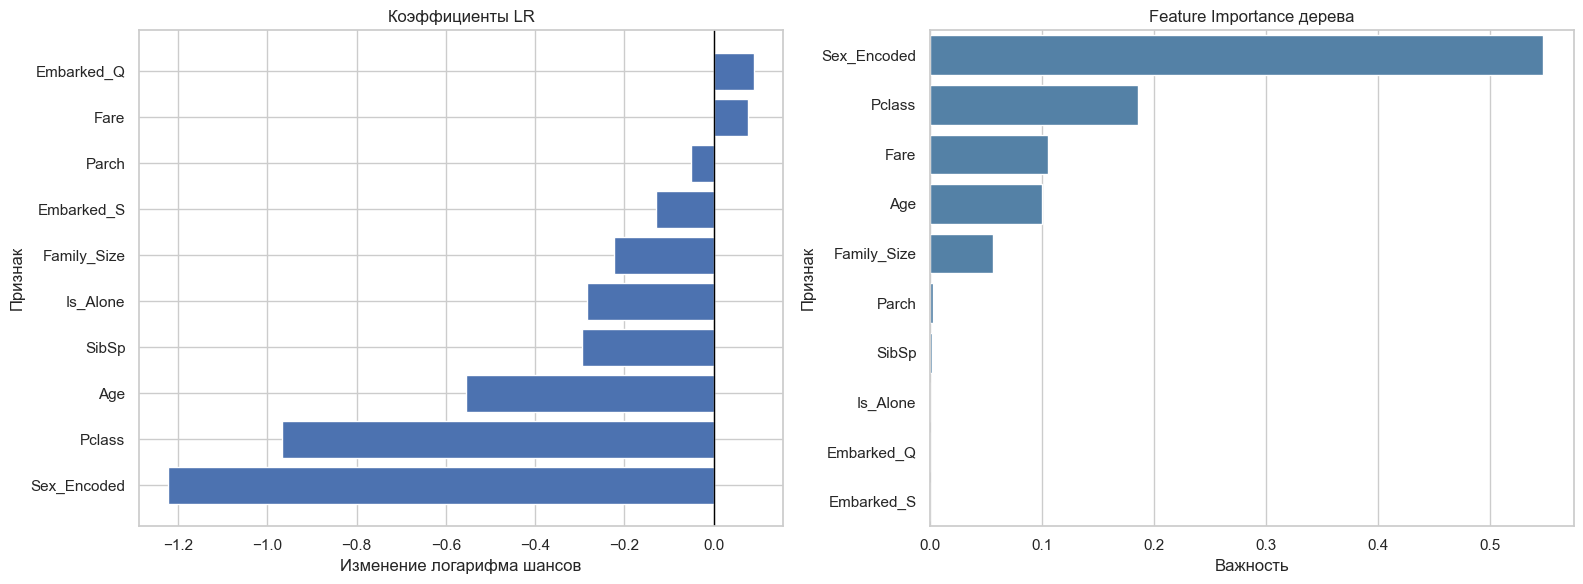

,Признак,Коэффициент
8,Embarked_Q,0.089916
5,Fare,0.077828
4,Parch,-0.051526
9,Embarked_S,-0.130004
6,Family_Size,-0.224116
7,Is_Alone,-0.283719
3,SibSp,-0.295030
2,Age,-0.556019
0,Pclass,-0.967947
1,Sex_Encoded,-1.222809


,Признак,Важность
1,Sex_Encoded,0.547662
0,Pclass,0.186186
5,Fare,0.105210
2,Age,0.099922
6,Family_Size,0.056601
4,Parch,0.002740
3,SibSp,0.001678
7,Is_Alone,0.000000
8,Embarked_Q,0.000000
9,Embarked_S,0.000000


Доля выживших по Sex:


,mean,count
Sex,,
female,0.742,314
male,0.189,577


Доля выживших по Pclass:


,mean,count
Pclass,,
1,0.630,216
2,0.473,184
3,0.242,491


Доля выживших по Embarked:


,mean,count
Embarked,,
C,0.554,168
Q,0.390,77
S,0.337,644


In [10]:
# Коэффициенты стандартизованной логистической регрессии.
coefficients = pd.DataFrame({"Признак":feature_cols,"Коэффициент":lr_model.coef_[0]})
coefficients = coefficients.sort_values("Коэффициент")
# Важности дерева решений.
importances = pd.DataFrame({"Признак":feature_cols,"Важность":dt_model.feature_importances_})
importances = importances.sort_values("Важность",ascending=False)
fig,axes = plt.subplots(1,2,figsize=(16,6))
axes[0].barh(coefficients["Признак"],coefficients["Коэффициент"])
axes[0].axvline(0,color="black",linewidth=1)
axes[0].set(title="Коэффициенты LR",xlabel="Изменение логарифма шансов",ylabel="Признак")
sns.barplot(data=importances,x="Важность",y="Признак",color="steelblue",ax=axes[1])
axes[1].set(title="Feature Importance дерева",xlabel="Важность",ylabel="Признак")
plt.tight_layout()
plt.show()
display(coefficients.sort_values("Коэффициент",ascending=False))
display(importances)
# Наблюдаемые доли из исходных данных (не модельные эффекты).
for col in ["Sex","Pclass","Embarked"]:
    print(f"Доля выживших по {col}:")
    display(train_df.groupby(col)["Survived"].agg(["mean","count"]).round(3))

**Бизнес-инсайты:** в представленных данных выживаемость сильно различается по полу и классу билета. При одинаковых остальных переменных коэффициенты LR показывают направление ассоциации, но не прямое причинное влияние. Три крупнейших положительных и три наиболее отрицательных коэффициента можно установить по таблице выше; их нельзя безусловно интерпретировать как причинные факторы. В случае дерева три признака с наибольшей важностью показаны в таблице важностей. Рекомендация для реального применения — проверять устойчивость таких зависимостей на независимых данных.

## 9. Функция предсказания
`predict_passenger` повторяет те же преобразования, использует обученный `LabelEncoder` и порядок из `feature_cols`. Демонстрируются пять контрастных профилей, обе обязательные модели и совпадение ответов.

In [11]:
# Принимаем один словарь с данными нового пассажира.
def predict_passenger(passenger_data, model, scaler, feature_cols, use_scaling=True):
    # Проверяем обязательные входные поля.
    required = {"Pclass","Sex","Age","SibSp","Parch","Fare","Embarked"}
    missing = required.difference(passenger_data)
    if missing:
        raise ValueError(f"Отсутствуют поля: {sorted(missing)}")
    if passenger_data["Sex"] not in {"female","male"}:
        raise ValueError("Sex должен быть 'female' или 'male'")
    if passenger_data["Embarked"] not in {"C","Q","S"}:
        raise ValueError("Embarked должен быть C, Q или S")
    # Преобразование воспроизводит обработку тренировочных записей.
    features = prepare_frame(pd.DataFrame([dict(passenger_data)]))[feature_cols]
    X_new = scaler.transform(features) if use_scaling else features
    # Возвращаем и класс, и вероятность его положительного исхода.
    return int(model.predict(X_new)[0]),float(model.predict_proba(X_new)[0,1])
# Пять пассажиров из условия, плюс разные ценовые и возрастные профили.
passengers = [
    {"Pclass":1,"Sex":"female","Age":25,"SibSp":1,"Parch":0,"Fare":100,"Embarked":"C"},
    {"Pclass":3,"Sex":"male","Age":30,"SibSp":0,"Parch":0,"Fare":7.25,"Embarked":"S"},
    {"Pclass":2,"Sex":"female","Age":5,"SibSp":3,"Parch":1,"Fare":30,"Embarked":"S"},
    {"Pclass":1,"Sex":"male","Age":60,"SibSp":0,"Parch":0,"Fare":200,"Embarked":"C"},
    {"Pclass":3,"Sex":"female","Age":22,"SibSp":0,"Parch":0,"Fare":8,"Embarked":"Q"}]
demonstration = []
for p in passengers:
    lr_pred,lr_prob = predict_passenger(p,lr_model,scaler,feature_cols)
    dt_pred,dt_prob = predict_passenger(p,dt_model,None,feature_cols,False)
    demonstration.append({**p,"LR класс":lr_pred,"LR вероятность, %":round(lr_prob*100,2),
                          "DT класс":dt_pred,"DT вероятность, %":round(dt_prob*100,2),
                          "Совпадают":lr_pred==dt_pred})
display(pd.DataFrame(demonstration))

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,LR класс,"LR вероятность, %",DT класс,"DT вероятность, %",Совпадают
0,1,female,25,1,0,100.00,C,1,96.10,1,100.00,True
1,3,male,30,0,0,7.25,S,0,7.66,0,11.00,True
2,2,female,5,3,1,30.00,S,1,80.72,1,100.00,True
3,1,male,60,0,0,200.00,C,0,30.64,0,30.91,True
4,3,female,22,0,0,8.00,Q,1,73.70,1,53.49,True


## 10. Сохранение модели
Сохраняем обе обязательные модели, бонусную модель, `scaler`, `LabelEncoder`, порядок признаков и JSON-метрики. Также сохраняются статистики предобработки, без которых невозможно в точности повторить прогноз на новом пассажире.

In [12]:
# Сохраняем версии моделей и компонентов подготовки.
joblib.dump(lr_model,MODEL_DIR/"lr_model.pkl")
joblib.dump(dt_model,MODEL_DIR/"dt_model.pkl")
joblib.dump(rf_model,MODEL_DIR/"rf_model.pkl")
joblib.dump(scaler,MODEL_DIR/"scaler.pkl")
joblib.dump(le_sex,MODEL_DIR/"le_sex.pkl")
# Статистики для воспроизводимого заполнения пропусков.
preprocessing = {"age_group_medians":{f"{int(k[0])}|{k[1]}":float(v)
                                         for k,v in age_group_medians.items()},
                 "global_age_median":global_age_median,
                 "embarked_mode":embarked_mode,"fare_median":fare_median}
joblib.dump(preprocessing,MODEL_DIR/"preprocessing.pkl")
# Важен исходный порядок признаков для scaler и модели.
(MODEL_DIR/"feature_cols.json").write_text(json.dumps(feature_cols,ensure_ascii=False,indent=2),encoding="utf-8")
metrics = {r["model"]:{k:float(v) for k,v in r.items() if k!="model"} for r in results}
(MODEL_DIR/"metrics.json").write_text(json.dumps(metrics,ensure_ascii=False,indent=2),encoding="utf-8")
print("Сохранены модели, scaler, encoder, предобработка и метрики:",list(MODEL_DIR.iterdir()))

Сохранены модели, scaler, encoder, предобработка и метрики: [WindowsPath('models/dt_model.pkl'), WindowsPath('models/feature_cols.json'), WindowsPath('models/le_sex.pkl'), WindowsPath('models/lr_model.pkl'), WindowsPath('models/metrics.json'), WindowsPath('models/preprocessing.pkl'), WindowsPath('models/rf_model.pkl'), WindowsPath('models/scaler.pkl')]


## 11. Загрузка модели из репозитория и быстрый инференс

In [16]:
# Используем только файлы, уже полученные после обучения.
lr_loaded = joblib.load(MODEL_DIR/"lr_model.pkl")
scaler_loaded = joblib.load(MODEL_DIR/"scaler.pkl")
features_loaded = json.loads((MODEL_DIR/"feature_cols.json").read_text(encoding="utf-8"))
assert features_loaded == feature_cols
for p in passengers[:3]:
    original = predict_passenger(p,lr_model,scaler,feature_cols)
    loaded = predict_passenger(p,lr_loaded,scaler_loaded,features_loaded)
    assert original[0] == loaded[0] and np.isclose(original[1],loaded[1])
print("Локальная загрузка: 3/3 предсказаний совпали без переобучения.")

GITHUB_RAW_BASE = (
    "https://raw.githubusercontent.com/"
    "CherepanovVyacheslav/ml-course-cherepanov/"
    "main/module-1-titanic"
)
if GITHUB_RAW_BASE:
    def download_trusted_binary(name):
        response = requests.get(f"{GITHUB_RAW_BASE}/models/{name}",timeout=20)
        response.raise_for_status()
        return response.content
    remote_model = joblib.load(BytesIO(download_trusted_binary("lr_model.pkl")))
    remote_scaler = joblib.load(BytesIO(download_trusted_binary("scaler.pkl")))
    remote_features = json.loads(download_trusted_binary("feature_cols.json").decode("utf-8"))
    assert remote_features == feature_cols
    for p in passengers[:3]:
        prediction_local = predict_passenger(p,lr_model,scaler,feature_cols)
        prediction_remote = predict_passenger(p,remote_model,remote_scaler,remote_features)
        assert prediction_local[0] == prediction_remote[0]
        assert np.isclose(prediction_local[1],prediction_remote[1])
    print("GitHub raw: 3/3 прогнозов совпали.")
else:
    print("Проверка raw GitHub ожидает публикации и заполнения GITHUB_RAW_BASE.")

Локальная загрузка: 3/3 предсказаний совпали без переобучения.
GitHub raw: 3/3 прогнозов совпали.


## 12. Выводы
### Что получилось
Выполнен EDA, построены обязательные LR и DT, а также бонусный Random Forest. Для всех моделей рассчитаны **фактические** holdout-метрики; ROC-AUC: LR **0.8489**, DT **0.8132**, RF **0.8401**; точные значения всех метрик находятся в `models/metrics.json`. Сравнение показывает наилучшую модель по ROC-AUC и разрыв между train/validation. Реализованы прогнозы для пяти профилей, сохранение и повторная локальная загрузка.

### Трудности и ограничения
`Age` содержит пропуски, `Cabin` почти полностью не заполнен, классы умеренно несбалансированы. Один holdout может давать нестабильную оценку; для практического ML нужна кросс-валидация. Kaggle `test.csv` не имеет целевой переменной, поэтому accuracy на нём нельзя измерить.

### Возможные улучшения
1. Извлечь `Title` из `Name` и сравнить качество.
2. Добавить взаимодействие `Pclass × Sex`.
3. Применять SMOTE только внутри train-фолдов с корректным пайплайном и проверить изменения.
4. Исследовать ансамбли (Random Forest, Gradient Boosting, XGBoost).
5. Подбирать гиперпараметры `GridSearchCV` на кросс-валидации.
6. Использовать `np.log1p(Fare)` и проверить влияние на LR.
7. Проверить калибровку вероятностей и устойчивость по группам пассажиров.

## 13. Список источников
1. Kaggle. [Titanic — Machine Learning from Disaster](https://www.kaggle.com/c/titanic). Описание данных и конкурса.
2. Kaggle. [Titanic — Data Dictionary](https://www.kaggle.com/c/titanic/data). Поля и кодировки.
3. scikit-learn. [LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html).
4. scikit-learn. [DecisionTreeClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html).
5. scikit-learn. [Model evaluation](https://scikit-learn.org/stable/modules/model_evaluation.html).
6. pandas. [User Guide](https://pandas.pydata.org/docs/user_guide/index.html).
7. Géron, A. (2022). *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow*. 3rd ed., O'Reilly.
8. McKinney, W. (2022). *Python for Data Analysis*. 3rd ed., O'Reilly.

## 14. Приложение
Весь выполняемый код содержится в предыдущих разделах с поясняющими комментариями; дополнительно создан **`full_code.py`**, автоматически объединяющий ячейки кода с разделителями `# %%` для Jupytext/обычного Python. Он служит полным листингом без дублирования сотен строк в Notebook.

**Зависимости** приведены в `requirements.txt` (версии зафиксированы при создании проекта).

**Запуск:**
```bash
cd module-1-titanic
python -m pip install -r requirements.txt
jupyter notebook notebook.ipynb
```

### Полный листинг кода (`# %%` — границы ячеек)

```python
# -*- coding: utf-8 -*-
# %%
# Основные импорты — используем фиксированную точку случайности.
from pathlib import Path
from time import perf_counter
from io import BytesIO
import json
import joblib
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import requests
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay, RocCurveDisplay,
                             classification_report, roc_curve)
# Все пути рассчитываются относительно папки модуля.
DATA_DIR = Path("data")
MODEL_DIR = Path("models")
EXAMPLE_DIR = Path("examples")
for folder in (DATA_DIR, MODEL_DIR, EXAMPLE_DIR):
    folder.mkdir(parents=True, exist_ok=True)
# Данные train.csv сохранены в проекте.
train_df = pd.read_csv(DATA_DIR / "train.csv")
test_path = DATA_DIR / "test.csv"
test_df = pd.read_csv(test_path) if test_path.is_file() else pd.DataFrame()
print(train_df.shape, test_df.shape)
print("Kaggle test.csv:", "имеется" if not test_df.empty else "отсутствует; загрузите из Kaggle")
assert len(train_df) == 891 and {"Survived","Pclass","Sex","Age"}.issubset(train_df.columns)
print("Доля классов:\n", train_df.Survived.value_counts(normalize=True).round(4))

# %%
# Отображаем образец и стандартные описательные статистики.
display(train_df.head())
train_df.info()
display(train_df.describe(include="all").T)
# Пропуски, распределение классов, асимметрия и эксцесс.
missing_table = pd.DataFrame({"Количество":train_df.isnull().sum(),
                              "Доля, %":train_df.isnull().mean().mul(100).round(2)})
display(missing_table)
display(train_df.select_dtypes("number").agg(["skew","kurt"]).T)
display(train_df["Survived"].value_counts())
# Сводка для подписей и аналитических выводов.
print("Выживаемость по полу:\n", train_df.groupby("Sex")["Survived"].mean().round(3))
print("Выживаемость по классу:\n", train_df.groupby("Pclass")["Survived"].mean().round(3))

# %%
# Сетка из шести графиков: единые заголовки, подписи и читаемый размер.
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 3, figsize=(19, 11))
sns.countplot(data=train_df, x="Survived", color="steelblue", ax=axes[0,0])
axes[0,0].set(title="Число пассажиров по исходу",xlabel="Выжил (0 — нет, 1 — да)",ylabel="Количество")
sns.histplot(data=train_df, x="Age", hue="Survived", kde=True, bins=25, ax=axes[0,1])
axes[0,1].set(title="Возраст и выживание",xlabel="Возраст, лет",ylabel="Число пассажиров")
sns.boxplot(data=train_df, x="Pclass", y="Age", hue="Survived", ax=axes[0,2])
axes[0,2].set(title="Возраст по классу и исходу",xlabel="Класс билета",ylabel="Возраст, лет")
# Для матрицы используем только числовые значения.
sns.heatmap(train_df.select_dtypes("number").corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=axes[1,0])
axes[1,0].set(title="Корреляции числовых полей",xlabel="Признаки",ylabel="Признаки")
sns.barplot(data=train_df, x="Sex", y="Survived", color="steelblue", errorbar=None, ax=axes[1,1])
axes[1,1].set(title="Доля выживших по полу",xlabel="Пол",ylabel="Доля выживших")
sns.barplot(data=train_df, x="Pclass", y="Survived", color="steelblue", errorbar=None, ax=axes[1,2])
axes[1,2].set(title="Доля выживших по классу",xlabel="Класс",ylabel="Доля выживших")
plt.tight_layout()
fig.savefig(EXAMPLE_DIR / "eda_plots.png", dpi=150, bbox_inches="tight")
plt.show()
# Дополнительный график показывает пропуски и их масштаб.
fig, ax = plt.subplots(figsize=(10,4))
missing_table["Доля, %"].sort_values().plot.barh(ax=ax)
ax.set(title="Доля пропусков по столбцам",xlabel="Пропуски, %",ylabel="Столбец")
plt.tight_layout()
plt.show()

# %%
# Стратифицированное разбиение ДО вычисления статистик очистки.
raw_train, raw_valid = train_test_split(
    train_df, test_size=0.2, random_state=42, stratify=train_df["Survived"])
# Статистики получаем исключительно по обучающей части.
age_group_medians = raw_train.groupby(["Pclass","Sex"])["Age"].median()
global_age_median = float(raw_train["Age"].median())
embarked_mode = raw_train["Embarked"].mode().iloc[0]
fare_median = float(raw_train["Fare"].median())
# Модельное кодирование пола: кодировку берём из LabelEncoder.
le_sex = LabelEncoder().fit(["female", "male"])
def prepare_frame(frame):
    # Рабочую копию создаём без изменения входных данных.
    df = frame.copy().drop(columns=["Cabin"], errors="ignore")
    df["Age"] = df.apply(
        lambda r: age_group_medians.get((r["Pclass"],r["Sex"]), np.nan)
        if pd.isna(r["Age"]) else r["Age"], axis=1)
    df["Age"] = df["Age"].fillna(global_age_median)
    df["Embarked"] = df["Embarked"].fillna(embarked_mode)
    df["Fare"] = df["Fare"].fillna(fare_median)
    # Новые признаки семьи и возрастных интервалов.
    df["Family_Size"] = df["SibSp"] + df["Parch"] + 1
    df["Is_Alone"] = (df["Family_Size"] == 1).astype(int)
    df["Age_Group"] = pd.cut(df["Age"], bins=[-0.01,12,18,35,60,120],
                             labels=["ребёнок","подросток","молодой","средний","старший"])
    df["Sex_Encoded"] = le_sex.transform(df["Sex"])
    # One-Hot: гарантируем колонки Embarked_Q, Embarked_S и базу C.
    dummies = pd.get_dummies(df["Embarked"],prefix="Embarked",dtype=int)
    for col in ["Embarked_Q", "Embarked_S"]:
        df[col] = dummies[col] if col in dummies else 0
    return df
train_ready = prepare_frame(raw_train)
valid_ready = prepare_frame(raw_valid)
feature_cols = ["Pclass","Sex_Encoded","Age","SibSp","Parch","Fare",
                "Family_Size","Is_Alone","Embarked_Q","Embarked_S"]
# Подготовленные данные проверяем на отсутствие NaN.
X_train, y_train = train_ready[feature_cols], train_ready["Survived"]
X_valid, y_valid = valid_ready[feature_cols], valid_ready["Survived"]
assert not X_train.isna().any().any() and not X_valid.isna().any().any()
print("Train:",X_train.shape,"Validation:",X_valid.shape)

# %%
# Стандартное масштабирование обучаем только на train.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_valid_scaled = scaler.transform(X_valid)
# Линейная классификация и замер продолжительности fit.
lr_model = LogisticRegression(penalty="l2",C=1.0,max_iter=1000,random_state=42)
t0 = perf_counter()
lr_model.fit(X_train_scaled,y_train)
lr_time = perf_counter()-t0
# Дерево обучается на немасштабированных признаках.
dt_model = DecisionTreeClassifier(max_depth=5,min_samples_split=5,
                                  min_samples_leaf=2,random_state=42)
t0 = perf_counter()
dt_model.fit(X_train,y_train)
dt_time = perf_counter()-t0
# Дополнительная модель для сравнения по тем же данным.
rf_model = RandomForestClassifier(n_estimators=200,min_samples_leaf=2,random_state=42,n_jobs=1)
t0 = perf_counter()
rf_model.fit(X_train,y_train)
rf_time = perf_counter()-t0
display(pd.DataFrame({"Модель":["Logistic Regression","Decision Tree","Random Forest"],
                      "Масштабирование":["да","нет","нет"],
                      "Время обучения, с":[lr_time,dt_time,rf_time]}).round(4))

# %%
# Единообразная функция для подсчёта всех метрик.
def assess(model, X, label, train_time):
    pred = model.predict(X)
    proba = model.predict_proba(X)[:,1]
    return {"model":label,"accuracy":accuracy_score(y_valid,pred),
            "precision":precision_score(y_valid,pred,zero_division=0),
            "recall":recall_score(y_valid,pred,zero_division=0),
            "f1":f1_score(y_valid,pred,zero_division=0),
            "roc_auc":roc_auc_score(y_valid,proba),
            "training_time_sec":train_time}
# Сравнение обязательных и бонусной моделей.
results = [
    assess(lr_model,X_valid_scaled,"logistic_regression",lr_time),
    assess(dt_model,X_valid,"decision_tree",dt_time),
    assess(rf_model,X_valid,"random_forest",rf_time)]
metrics_df = pd.DataFrame(results).set_index("model")
display(metrics_df.round(4))
# Детальные отчёты по двум обязательным моделям.
for title, model, features in [
    ("Logistic Regression",lr_model,X_valid_scaled),
    ("Decision Tree",dt_model,X_valid)]:
    print("\n",title,"\n",classification_report(y_valid,model.predict(features),zero_division=0))

# %%
# Матрицы ошибок сравниваем на общей фигуре.
fig, axes = plt.subplots(1,2,figsize=(12,4))
for ax, (label,model,Xv) in zip(axes,[
    ("Logistic Regression",lr_model,X_valid_scaled),
    ("Decision Tree",dt_model,X_valid)]):
    ConfusionMatrixDisplay.from_predictions(y_valid,model.predict(Xv),
                                              display_labels=["Погиб","Выжил"],ax=ax,cmap="Blues")
    ax.set(title=f"Матрица ошибок: {label}",xlabel="Предсказано",ylabel="Истинно")
plt.tight_layout()
fig.savefig(EXAMPLE_DIR/"confusion_matrices.png",dpi=150,bbox_inches="tight")
plt.show()
# Три ROC-кривые и диагональ случайного классификатора.
fig,ax = plt.subplots(figsize=(8,6))
for label, model, Xv in [
    ("Logistic Regression",lr_model,X_valid_scaled),
    ("Decision Tree",dt_model,X_valid),
    ("Random Forest",rf_model,X_valid)]:
    RocCurveDisplay.from_estimator(model,Xv,y_valid,name=label,ax=ax)
ax.plot([0,1],[0,1],"k--",label="Случайная модель")
ax.set(title="ROC-кривые (валидация)",xlabel="False Positive Rate",ylabel="True Positive Rate")
ax.legend()
plt.tight_layout()
fig.savefig(EXAMPLE_DIR/"roc_curves.png",dpi=150,bbox_inches="tight")
plt.show()

# %%
# Разница между обучающей и валидационной ROC-AUC — индикатор переобучения.
overfit = []
for label,model,Xt,Xv in [
    ("LR",lr_model,X_train_scaled,X_valid_scaled),
    ("DT",dt_model,X_train,X_valid),
    ("RF",rf_model,X_train,X_valid)]:
    tr_auc = roc_auc_score(y_train,model.predict_proba(Xt)[:,1])
    va_auc = roc_auc_score(y_valid,model.predict_proba(Xv)[:,1])
    overfit.append({"Модель":label,"AUC train":tr_auc,"AUC valid":va_auc,"Разрыв":tr_auc-va_auc})
display(pd.DataFrame(overfit).round(4))
best = metrics_df["roc_auc"].idxmax()
print("Лучшая по ROC-AUC:",best,round(metrics_df.loc[best,"roc_auc"],4))

# %%
# Коэффициенты стандартизованной логистической регрессии.
coefficients = pd.DataFrame({"Признак":feature_cols,"Коэффициент":lr_model.coef_[0]})
coefficients = coefficients.sort_values("Коэффициент")
# Важности дерева решений.
importances = pd.DataFrame({"Признак":feature_cols,"Важность":dt_model.feature_importances_})
importances = importances.sort_values("Важность",ascending=False)
fig,axes = plt.subplots(1,2,figsize=(16,6))
axes[0].barh(coefficients["Признак"],coefficients["Коэффициент"])
axes[0].axvline(0,color="black",linewidth=1)
axes[0].set(title="Коэффициенты LR",xlabel="Изменение логарифма шансов",ylabel="Признак")
sns.barplot(data=importances,x="Важность",y="Признак",color="steelblue",ax=axes[1])
axes[1].set(title="Feature Importance дерева",xlabel="Важность",ylabel="Признак")
plt.tight_layout()
plt.show()
display(coefficients.sort_values("Коэффициент",ascending=False))
display(importances)
# Наблюдаемые доли из исходных данных (не модельные эффекты).
for col in ["Sex","Pclass","Embarked"]:
    print(f"Доля выживших по {col}:")
    display(train_df.groupby(col)["Survived"].agg(["mean","count"]).round(3))

# %%
# Принимаем один словарь с данными нового пассажира.
def predict_passenger(passenger_data, model, scaler, feature_cols, use_scaling=True):
    # Проверяем обязательные входные поля.
    required = {"Pclass","Sex","Age","SibSp","Parch","Fare","Embarked"}
    missing = required.difference(passenger_data)
    if missing:
        raise ValueError(f"Отсутствуют поля: {sorted(missing)}")
    if passenger_data["Sex"] not in {"female","male"}:
        raise ValueError("Sex должен быть 'female' или 'male'")
    if passenger_data["Embarked"] not in {"C","Q","S"}:
        raise ValueError("Embarked должен быть C, Q или S")
    # Преобразование воспроизводит обработку тренировочных записей.
    features = prepare_frame(pd.DataFrame([dict(passenger_data)]))[feature_cols]
    X_new = scaler.transform(features) if use_scaling else features
    # Возвращаем и класс, и вероятность его положительного исхода.
    return int(model.predict(X_new)[0]),float(model.predict_proba(X_new)[0,1])
# Пять пассажиров из условия, плюс разные ценовые и возрастные профили.
passengers = [
    {"Pclass":1,"Sex":"female","Age":25,"SibSp":1,"Parch":0,"Fare":100,"Embarked":"C"},
    {"Pclass":3,"Sex":"male","Age":30,"SibSp":0,"Parch":0,"Fare":7.25,"Embarked":"S"},
    {"Pclass":2,"Sex":"female","Age":5,"SibSp":3,"Parch":1,"Fare":30,"Embarked":"S"},
    {"Pclass":1,"Sex":"male","Age":60,"SibSp":0,"Parch":0,"Fare":200,"Embarked":"C"},
    {"Pclass":3,"Sex":"female","Age":22,"SibSp":0,"Parch":0,"Fare":8,"Embarked":"Q"}]
demonstration = []
for p in passengers:
    lr_pred,lr_prob = predict_passenger(p,lr_model,scaler,feature_cols)
    dt_pred,dt_prob = predict_passenger(p,dt_model,None,feature_cols,False)
    demonstration.append({**p,"LR класс":lr_pred,"LR вероятность, %":round(lr_prob*100,2),
                          "DT класс":dt_pred,"DT вероятность, %":round(dt_prob*100,2),
                          "Совпадают":lr_pred==dt_pred})
display(pd.DataFrame(demonstration))

# %%
# Сохраняем версии моделей и компонентов подготовки.
joblib.dump(lr_model,MODEL_DIR/"lr_model.pkl")
joblib.dump(dt_model,MODEL_DIR/"dt_model.pkl")
joblib.dump(rf_model,MODEL_DIR/"rf_model.pkl")
joblib.dump(scaler,MODEL_DIR/"scaler.pkl")
joblib.dump(le_sex,MODEL_DIR/"le_sex.pkl")
# Статистики для воспроизводимого заполнения пропусков.
preprocessing = {"age_group_medians":{f"{int(k[0])}|{k[1]}":float(v)
                                         for k,v in age_group_medians.items()},
                 "global_age_median":global_age_median,
                 "embarked_mode":embarked_mode,"fare_median":fare_median}
joblib.dump(preprocessing,MODEL_DIR/"preprocessing.pkl")
# Важен исходный порядок признаков для scaler и модели.
(MODEL_DIR/"feature_cols.json").write_text(json.dumps(feature_cols,ensure_ascii=False,indent=2),encoding="utf-8")
metrics = {r["model"]:{k:float(v) for k,v in r.items() if k!="model"} for r in results}
(MODEL_DIR/"metrics.json").write_text(json.dumps(metrics,ensure_ascii=False,indent=2),encoding="utf-8")
print("Сохранены модели, scaler, encoder, предобработка и метрики:",list(MODEL_DIR.iterdir()))

# %%
# Используем только файлы, уже полученные после обучения.
lr_loaded = joblib.load(MODEL_DIR/"lr_model.pkl")
scaler_loaded = joblib.load(MODEL_DIR/"scaler.pkl")
features_loaded = json.loads((MODEL_DIR/"feature_cols.json").read_text(encoding="utf-8"))
assert features_loaded == feature_cols
for p in passengers[:3]:
    original = predict_passenger(p,lr_model,scaler,feature_cols)
    loaded = predict_passenger(p,lr_loaded,scaler_loaded,features_loaded)
    assert original[0] == loaded[0] and np.isclose(original[1],loaded[1])
print("Локальная загрузка: 3/3 предсказаний совпали без переобучения.")
# Укажите свой реально опубликованный адрес вида:
# https://raw.githubusercontent.com/USERNAME/ml-course-SURNAME/main/module-1-titanic
GITHUB_RAW_BASE = ""  # Заполнить только после публикации в GitHub.
if GITHUB_RAW_BASE:
    def download_trusted_binary(name):
        # Загрузку выполняйте ТОЛЬКО из собственного доверенного репозитория.
        response = requests.get(f"{GITHUB_RAW_BASE}/models/{name}",timeout=20)
        response.raise_for_status()
        return response.content
    # Загружаем ровно те объекты, которые нужны для инференса.
    remote_model = joblib.load(BytesIO(download_trusted_binary("lr_model.pkl")))
    remote_scaler = joblib.load(BytesIO(download_trusted_binary("scaler.pkl")))
    remote_features = json.loads(download_trusted_binary("feature_cols.json").decode("utf-8"))
    assert remote_features == feature_cols
    for p in passengers[:3]:
        prediction_local = predict_passenger(p,lr_model,scaler,feature_cols)
        prediction_remote = predict_passenger(p,remote_model,remote_scaler,remote_features)
        assert prediction_local[0] == prediction_remote[0]
        assert np.isclose(prediction_local[1],prediction_remote[1])
    print("GitHub raw: 3/3 прогнозов совпали.")
else:
    print("Проверка raw GitHub ожидает публикации и заполнения GITHUB_RAW_BASE.")

```
